In [122]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

In [16]:
def closed_form(X,Y):
    '''
    Function to compute the closed form solution of linear regression
    Parameters:
    Input:
    X : numpy array of shape (n_samples, n_features+1)
        The input data.
    Y : numpy array of shape (n_samples,1)
        The target values.
    Output:
    w : numpy array of shape (n_features+1,1)
        The weights and bias of the linear regression model.

    '''
    # Add a column of ones to X to account for the bias term
    X = np.column_stack((np.ones(X.shape[0]), X))
    # Compute the closed form solution using the normal equation
    w = np.dot(np.linalg.inv(np.dot(X.T, X)), np.dot(X.T, Y))
    return w

In [ ]:
def mean_squared_error(y_true, y_pred):
    '''
    Function to compute the mean squared error
    Parameters:
    Input:
    y_true : numpy array of shape (n_samples,1)
        The true target values.
    y_pred : numpy array of shape (n_samples,1)
        The predicted target values.
    Output:
    mse : float
        The mean squared error.

    '''
    mse = np.mean((y_true - y_pred) ** 2)
    return mse

In [84]:
def forward_pass(X, w):
    '''
    Function to compute the forward pass of linear regression
    Parameters:
    Input:
    X : numpy array of shape (n_samples, n_features+1)
        The input data.
    w : numpy array of shape (n_features+1,1)
        The weights and bias of the linear regression model.
    Output:
    y_pred : numpy array of shape (n_samples,1)
        The predicted target values.

    '''
    X = np.column_stack((np.ones(X.shape[0]), X))
    y_pred = np.dot(X, w)
    return y_pred

In [155]:
def batch_gradient_descent(X, Y, w_init=None, learning_rate = 0.01, n_iterations = 1000):
    '''
    Function to compute the gradient descent of linear regression
    Parameters:
    Input:
    X : numpy array of shape (n_samples, n_features+1)
        The input data.
    Y : numpy array of shape (n_samples,1)
        The target values.
    w_init : numpy array of shape (n_features+1,1)
        The initial weights and bias of the linear regression model.
    learning_rate : float
        The learning rate for gradient descent.
    n_iterations : int
        The number of iterations for gradient descent.
    Output:
    w : numpy array of shape (n_features+1,1)
        The weights and bias of the linear regression model after gradient descent.
    ''' 
    
    if w_init is None:
        w_init = np.zeros((X.shape[1]+1, 1))
    current_w = w_init.copy()
    w = w_init
    mse_list = {}
    for i in range(n_iterations):
        y_pred = forward_pass(X, current_w)
        mse = mean_squared_error(Y, y_pred)
        mse_list[i] = mse
        error = y_pred - Y
        gradient = (2 * np.dot(np.column_stack((np.ones(X.shape[0]), X)).T, error) / X.shape[0])
        current_w -= learning_rate * gradient
        w = np.column_stack((current_w,w))
        if mse < 1e-6:
            break

            
    return w, mse_list

In [200]:
def generate_data(n_samples=100, n_features=1, noise=0.1):
    '''
    Function to generate synthetic data for linear regression
    Parameters:
    Input:
    n_samples : int
        The number of samples to generate.
    n_features : int
        The number of features to generate.
    noise : float
        The standard deviation of the Gaussian noise added to the target values.
    Output:
    X : numpy array of shape (n_samples, n_features)
        The input data.
    Y : numpy array of shape (n_samples,1)
        The target values.
    true_w : numpy array of shape (n_features,1)
        The true weights used to generate the target values.
    true_bias : numpy array of shape (1,1)
        The true bias used to generate the target values.

    '''
    rng = np.random.default_rng(seed=42)
    X = rng.random((n_samples, n_features)) 
    true_w = rng.standard_normal((n_features, 1))
    true_bias = rng.standard_normal((1, 1))
    Y = np.dot(X, true_w) + true_bias + noise * rng.standard_normal((n_samples, 1))
    return X, Y, true_w, true_bias


In [261]:
def stochastic_gradient_descent(X, Y, w_init=None, learning_rate = 0.01, n_iterations = 1000, batch_size=1):
    '''
    Function to compute the gradient descent of linear regression
    Parameters:
    Input:
    X : numpy array of shape (n_samples, n_features+1)
        The input data.
    Y : numpy array of shape (n_samples,1)
        The target values.
    w_init : numpy array of shape (n_features+1,1)
        The initial weights and bias of the linear regression model.
    learning_rate : float
        The learning rate for gradient descent.
    n_iterations : int
        The number of iterations for gradient descent.
    batch_size : int
        The number of samples to use for each gradient descent step.
    Output:
    w : numpy array of shape (n_features+1,1)
        The weights and bias of the linear regression model after gradient descent.
    ''' 
    
    if w_init is None:
        w_init = np.zeros((X.shape[1]+1, 1))
    current_w = w_init.copy()
    w = w_init
    mse_list = {}
    for i in range(n_iterations):
        y_pred = forward_pass(X[i:i+batch_size], current_w)
        mse = mean_squared_error(Y[i:i+batch_size], y_pred)
        mse_list[i] = mse
        error = y_pred - Y[i:i+batch_size]
        gradient = (2 * np.dot(np.column_stack((np.ones(X[i:i+batch_size].shape[0]), X[i:i+batch_size])).T, error) / X[i:i+batch_size].shape[0])
        current_w -= learning_rate * gradient
        w = np.column_stack((current_w,w))
        if mse < 1e-6:
            break

            
    return w, mse_list

In [265]:
def mini_batch_gradient_descent(X, Y, w_init=None, learning_rate = 0.01, n_iterations = 1000, batch_size=32):
    '''
    Function to compute the gradient descent of linear regression
    Parameters:
    Input:
    X : numpy array of shape (n_samples, n_features+1)
        The input data.
    Y : numpy array of shape (n_samples,1)
        The target values.
    w_init : numpy array of shape (n_features+1,1)
        The initial weights and bias of the linear regression model.
    learning_rate : float
        The learning rate for gradient descent.
    n_iterations : int
        The number of iterations for gradient descent.
    batch_size : int
        The number of samples to use for each gradient descent step.
    Output:
    w : numpy array of shape (n_features+1,1)
        The weights and bias of the linear regression model after gradient descent.
    mse_list : dict
        A dictionary containing the mean squared error at each iteration.  
    '''
    if w_init is None:
        w_init = np.zeros((X.shape[1]+1, 1))
    current_w = w_init.copy()
    w = w_init
    mse_list = {}
    for i in range(n_iterations):
        # Shuffle the data
        indices = np.random.permutation(X.shape[0])
        X_shuffled = X[indices]
        Y_shuffled = Y[indices]
        
        for j in range(0, X.shape[0], batch_size):
            X_batch = X_shuffled[j:j+batch_size]
            Y_batch = Y_shuffled[j:j+batch_size]
            
            y_pred = forward_pass(X_batch, current_w)
            mse = mean_squared_error(Y_batch, y_pred)
            mse_list[i] = mse
            error = y_pred - Y_batch
            gradient = (2 * np.dot(np.column_stack((np.ones(X_batch.shape[0]), X_batch)).T, error) / X_batch.shape[0])
            current_w -= learning_rate * gradient
            w = np.column_stack((current_w,w))
            
        if mse < 1e-6:
            break
    return w, mse_list

In [ ]:
0.1 * np.random.randn(100, 1)

array([[ 0.14535341],
       [-0.02646568],
       [ 0.27201692],
       [ 0.06256673],
       [-0.08571576],
       [-0.10708925],
       [ 0.04824724],
       [-0.02234628],
       [ 0.07140005],
       [ 0.04732376],
       [-0.00728289],
       [-0.08467937],
       [-0.15148472],
       [-0.0446515 ],
       [ 0.08563988],
       [ 0.02140937],
       [-0.12457388],
       [ 0.01731809],
       [ 0.03853174],
       [-0.08838574],
       [ 0.01537251],
       [ 0.00582087],
       [-0.11429703],
       [ 0.03577874],
       [ 0.05607845],
       [ 0.10830512],
       [ 0.10538021],
       [-0.13776694],
       [-0.0937825 ],
       [ 0.05150353],
       [ 0.0513786 ],
       [ 0.05150477],
       [ 0.38527315],
       [ 0.05708905],
       [ 0.11355656],
       [ 0.09540018],
       [ 0.06513913],
       [-0.03152692],
       [ 0.07589692],
       [-0.07728252],
       [-0.02368186],
       [-0.04853635],
       [ 0.00818741],
       [ 0.23146586],
       [-0.18672652],
       [ 0

In [242]:
X[0:0+1]

array([[0.77395605, 0.43887844]])

In [244]:
X, Y, true_weights, true_bias = generate_data(n_samples=100, n_features=2, noise=0.1)

In [245]:
closed_form_weights = closed_form(X, Y)

In [246]:
closed_form_weights

array([[-0.00988772],
       [ 0.60783404],
       [-0.36615974]])

In [247]:
true_weights

array([[ 0.64332679],
       [-0.39460512]])

In [248]:
true_bias

array([[-0.00512187]])

In [221]:
y_pred = forward_pass( X, closed_form_weights)

In [222]:
mse = mean_squared_error(Y, y_pred)
mse

0.01022260146473393

In [232]:
batch_gradient_descent_weights, mse_list = batch_gradient_descent(X, Y, learning_rate=0.01, n_iterations=4000)

In [233]:
batch_gradient_descent_weights[:,0]

array([-0.00848835,  0.6050819 , -0.3662218 ])

In [234]:
next(reversed(mse_list.items()))

(3999, 0.010223180053224678)

In [254]:
stochastic_gradient_descent_weights, mse_list = stochastic_gradient_descent(X, Y, learning_rate=0.01, n_iterations=4000)

In [256]:
stochastic_gradient_descent_weights[:,0]

array([0.02960408, 0.03132348, 0.00732812])

In [257]:
next(reversed(mse_list.items()))

(15, 3.6070442066323044e-07)

In [266]:
mini_batch_gradient_descent_weights, mse_list = mini_batch_gradient_descent(X, Y, learning_rate=0.01, n_iterations=4000)

In [267]:
mini_batch_gradient_descent_weights[:,0]

array([-0.00961746,  0.60788547, -0.36638721])

In [268]:
next(reversed(mse_list.items()))

(3999, 0.003142049878934044)

0.003142049878934044

In [258]:
y_pred = forward_pass(X,stochastic_gradient_descent_weights[:,0])

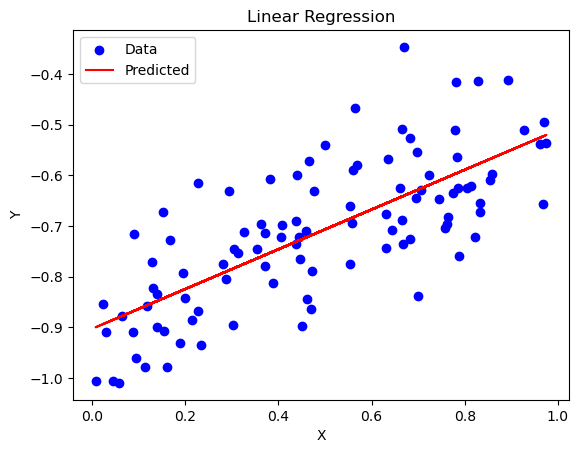

In [213]:
y_pred = forward_pass(X,closed_form_weights)
plt.scatter(X[:,0], Y, color='blue', label='Data')
plt.plot(X[:,0], y_pred, color='red', label='Predicted')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Linear Regression')
plt.legend()
plt.show()

In [259]:
mean_squared_error(Y, y_pred)

0.048855150791984304

In [149]:
def plot_regression_line(X, Y, w):
    '''
    Function to plot the regression line
    Parameters:
    Input:
    X : numpy array of shape (n_samples, n_features+1)
        The input data.
    Y : numpy array of shape (n_samples,1)
        The target values.
    w : numpy array of shape (n_features+1,1)
        The weights and bias of the linear regression model.
    Output:
    None

    '''
    y_pred = forward_pass(X, w)
    plt.scatter(X[:,0], Y, color='blue', label='Data')
    plt.plot(X[:,0], y_pred, color='red', label='Predicted')
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Linear Regression')
    plt.legend()
    plt.show()

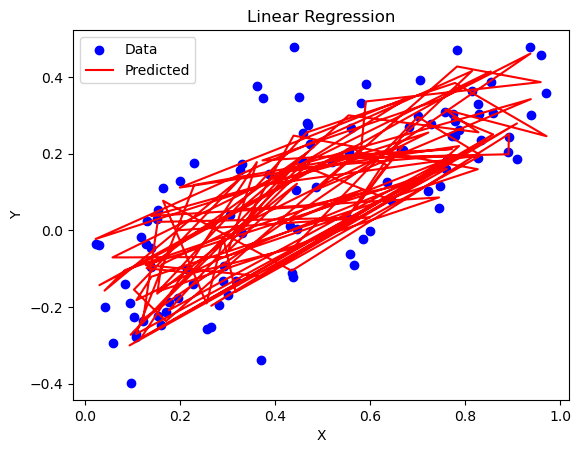

In [226]:
plot_regression_line(X, Y, batch_gradient_descent_weights[:,0])

In [101]:
mean_squared_error(Y, y_pred)

0.008726827467981594

In [227]:
X.mean()

0.49386955433629576

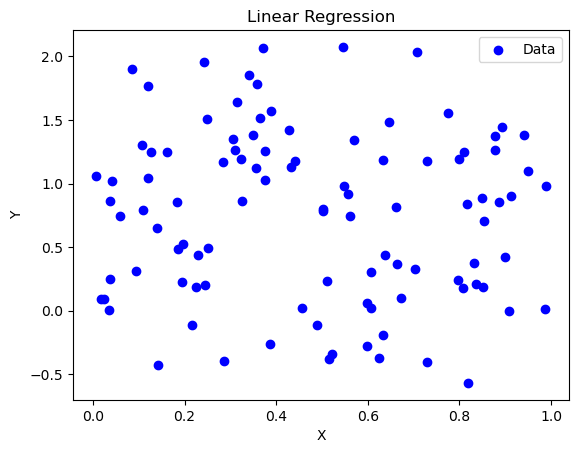

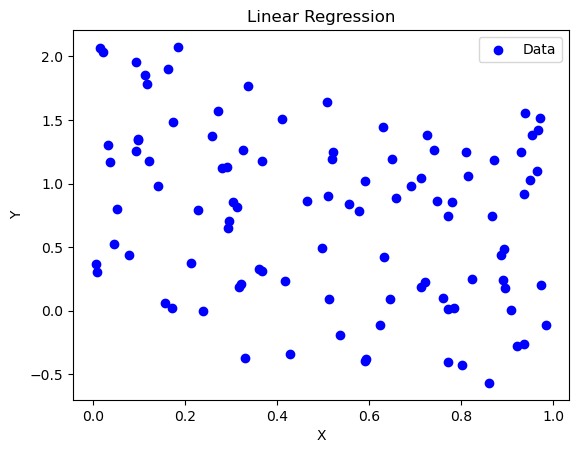

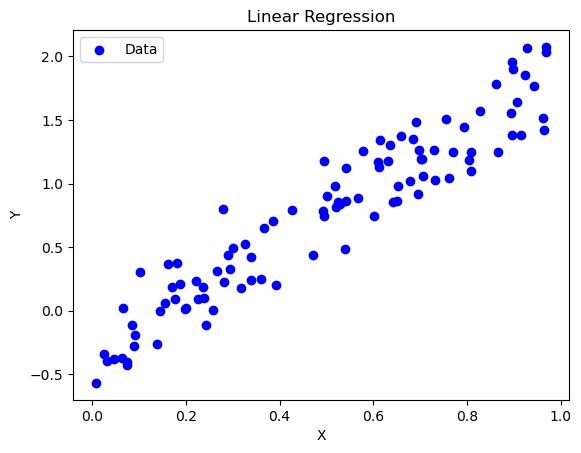

In [106]:
for i in range(X.shape[1]):
    plt.scatter(X[:, i], Y, color='blue', label='Data')
    #plt.plot(X[:,0], y_pred, color='red', label='Predicted')
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Linear Regression')
    plt.legend()
    plt.show()

In [238]:
df = pd.DataFrame({f"X_{i}": X[:, i] for i in range(X.shape[1])}, columns=[f"X_{i}" for i in range(X.shape[1])])
df["Y"] = Y

In [239]:
df.head()

,X_0,X_1,Y
0,0.773956,0.438878,0.303257
1,0.858598,0.697368,0.305810
2,0.094177,0.975622,-0.188772
3,0.761140,0.786064,0.183413
4,0.128114,0.450386,-0.036034


In [240]:
df.corr()

,X_0,X_1,Y
X_0,1.000000,0.049533,0.742709
X_1,0.049533,1.000000,-0.444639
Y,0.742709,-0.444639,1.000000


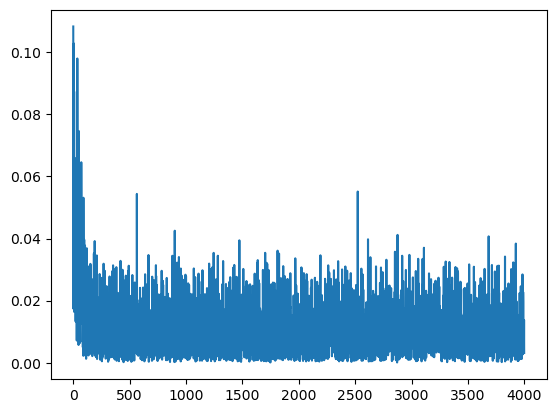

In [269]:
plt.plot(list(mse_list.keys()), list(mse_list.values()))